# 01 · Index time series

Builds **monthly** index time series for every model, scenario and member in `inputs.yaml`,
writes them to `interim_outputs/01_indices/{model}_monthly.nc`, and plots everything for
checking. Annualisation and lag choices are left to step 3.

| index | definition | units |
|---|---|---|
| `gmsat` | global-mean near-surface air temperature | K |
| `nino34` | Niño 3.4 box (5°S–5°N, 170°–120°W) mean SST | K |
| `trop_sst` | 20°S–20°N mean ocean SST | K |
| `nino34_rel` | `nino34` − `trop_sst` | K |
| `sia_nh` | Arctic (lat > 0) sea-ice area | 10⁶ km² |
| `ism` | land-only precipitation, 5–40°N, 60–100°E | mm/day |

Definitions come from `choices` in `inputs.yaml`. Implementation details to be aware of:

- **Monthly output only.** The step 3 baseline case is calendar-year GMSAT, ENSO-adjusted
  with a lagged Niño 3.4 regression; `indices.annual_mean`, `seasonal_mean` and
  `annual_indices` derive annual values with any start month.
- **SAI series start at the branch point**, as on file. A lagged ENSO term for the first SAI
  years needs pre-branch months; `indices.stitch_from_baseline(sai, base, n_months)` takes
  them from the paired ssp245 member (before branching, the SAI run *is* that member).
- **Sea-ice units** (fraction vs %) are decided from the values, not the `units` attribute.
- **Sea-ice area** needs true cell areas, so it uses areacella (atmosphere-grid `siconca`)
  or areacello (ocean-grid `siconc`).
- **Masks.** SST indices on the atmosphere grid use ocean cells only (`ocean_mask`). The
  monsoon index uses land cells only (`ism.land_mask`; "majority" = sftlf > 50%).
- **Indices are raw means, not anomalies.** Baselines and detrending come in step 3.
- The checks and plots below use **calendar-year means** (Sep for sea ice, JJA for the
  monsoon), computed here for display only and not saved.

In [1]:
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cftime
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from inputs import (load_config, is_configured, expected_files, check_existence,
                    load_member, open_fx, month_index)
from indices import (gmsat_monthly, sst_monthly, seaice_monthly, ism_monthly,
                     annual_indices, ANNUAL_INDICES, UNITS)

CONFIG = os.environ.get("TOE_CONFIG", "inputs.yaml")
OUT = Path(os.environ.get("TOE_OUT", "interim_outputs/01_indices"))
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

N_WORKERS = 12                # members processed in parallel
CHUNKS = "auto"   # dask chunks aligned with each file's stored chunks (~128 MB each)

cfg = load_config(CONFIG)
choices = cfg["choices"]
MODELS = [m for m in cfg["run"]["models"] if is_configured(cfg, m)]
SCENARIOS = cfg["run"]["scenarios"]
SAI_SCENARIOS = [s for s in SCENARIOS if (cfg["scenarios"][s] or {}).get("kind") == "sai"]
print("models:", MODELS)
print("choices:", {k: v for k, v in choices.items()})

models: ['UKESM1-1', 'MIROC-ES2H', 'CESM2-WACCM']
choices: {'ocean_mask': 'strict', 'nino34_box': {'lat': [-5, 5], 'lon': [190, 240]}, 'relative_nino34_band': {'lat': [-20, 20]}, 'annualisation': 'calendar', 'complete_years_only': True, 'enso_adjustment': {'method': 'lagged_regression', 'lag_months': None}, 'seaice': {'hemisphere': 'north', 'month': 9}, 'ism': {'lat': [5, 40], 'lon': [60, 100], 'months': [6, 7, 8], 'land_mask': 'majority'}}


## 1. Resolve members and load fixed fields

In [2]:
import time
t0 = time.perf_counter()
print("Resolving file patterns (S3 listings)...", flush=True)
files = check_existence(expected_files(cfg, models=MODELS))
present = files[files.status == "present"]
print(f"done in {time.perf_counter() - t0:.0f}s")
print(present.groupby(["model", "scenario"]).size().unstack(fill_value=0))

print()
print("Loading fixed fields...", flush=True)
fx = {}
for model in MODELS:
    for name in ("areacella", "areacello", "sftlf"):
        t1 = time.perf_counter()
        da = open_fx(cfg, model, name)
        fx[(model, name)] = None if da is None else da.load()
        if da is not None:
            print(f"  {model:12} {name:9} {time.perf_counter() - t1:5.1f}s", flush=True)

Resolving file patterns (S3 listings)...


done in 13s
scenario     G6-1.5K-HiLLA  G6-1.5K-SAI  historical  ssp245
model                                                      
CESM2-WACCM             12           12           3      12
MIROC-ES2H              40           40           0      40
UKESM1-1                12            9           0      12

Loading fixed fields...


  UKESM1-1     areacella   2.8s


  UKESM1-1     sftlf       0.0s


  MIROC-ES2H   areacella   0.0s


...

  MIROC-ES2H   sftlf       0.0s


  CESM2-WACCM  areacella   0.0s


  CESM2-WACCM  areacello   0.0s


  CESM2-WACCM  sftlf       0.0s


/home/jovyan/.local/lib/python3.12/site-packages/xarray/conventions.py:205: SerializationWarning: variable 'areacella' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/home/jovyan/.local/lib/python3.12/site-packages/xarray/conventions.py:205: SerializationWarning: variable 'areacello' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
/home/jovyan/.local/lib/python3.12/site-packages/xarray/conventions.py:205: SerializationWarning: variable 'sftlf' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)


## 2. Monthly indices per member

Each member is opened lazily and reduced to area means. Errors are collected rather than
stopping the run.

In [3]:
import time
from concurrent.futures import as_completed
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = None

try:
    import dask
    def compute(d):
        with dask.config.set(scheduler="synchronous"):
            return {k: v.compute() for k, v in d.items()}
    chunks = CHUNKS
except ImportError:
    def compute(d):
        return {k: v.load() for k, v in d.items()}
    chunks = None

def process(row):
    key = (row.model, row.scenario, row.member, row.role)
    t0 = time.perf_counter()
    try:
        da = load_member(row, chunks=chunks)[row["var"]]
        area = fx[(row.model, "areacello" if row.grid_expected == "ocean" else "areacella")]
        sftlf = fx[(row.model, "sftlf")]
        if row.role == "gmsat":
            out, meta = gmsat_monthly(da, area)
        elif row.role == "sst":
            out, meta = sst_monthly(da, area, sftlf, row.grid_expected, choices)
        elif row.role == "seaice":
            out, meta = seaice_monthly(da, area, choices)
        elif row.role == "precip":
            out, meta = ism_monthly(da, area, sftlf, choices)
        else:
            raise ValueError(f"unknown role {row.role}")
        out = compute(out)
    except Exception as e:
        out, meta = {}, {"error": f"{type(e).__name__}: {e}"}
    meta["seconds"] = round(time.perf_counter() - t0, 1)
    return key, out, meta

# Largest members first, so slow ones don't trail at the end
todo = present.sort_values("size_bytes", ascending=False, na_position="last")
total_mb = todo.size_bytes.sum() / 1e6
print(f"{len(todo)} members, {total_mb / 1e3:.1f} GB, {N_WORKERS} workers")

results, done_mb, t_start = [], 0.0, time.perf_counter()
bar = tqdm(total=len(todo), unit="member") if tqdm else None
log = bar.write if bar else (lambda msg: print(msg, flush=True))

with ThreadPoolExecutor(N_WORKERS) as ex:
    futures = {ex.submit(process, r): r for _, r in todo.iterrows()}
    for i, fut in enumerate(as_completed(futures), 1):
        row = futures[fut]
        key, out, meta = fut.result()
        results.append((key, out, meta))
        mb = row.size_bytes / 1e6 if pd.notna(row.size_bytes) else 0.0
        done_mb += mb
        elapsed = time.perf_counter() - t_start
        eta = elapsed / done_mb * (total_mb - done_mb) if done_mb else float("nan")
        status = "x" if "error" in meta else "ok"
        size = f"{mb:6.0f} MB" if mb else "     ? MB"
        msg = (f"{status:>2} [{i:3d}/{len(todo)}] {row.model:<12} {row.scenario:<14} "
               f"{row.role:<7} {row.member:<4} {size} {meta['seconds']:6.1f}s")
        if "error" in meta:
            msg += f"   {meta['error']}"
        log(msg)
        if bar:
            bar.set_postfix_str(f"{done_mb / total_mb:.0%} of data, ETA {eta / 60:.0f} min")
            bar.update()
        elif i % 10 == 0:
            print(f"   ... {done_mb / total_mb:.0%} of data in {elapsed / 60:.1f} min, "
                  f"ETA {eta / 60:.0f} min", flush=True)
if bar:
    bar.close()

monthly = {}       # (model, scenario, member) -> {index: DataArray(time)}
prov = []
for (model, scen, member, role), out, meta in results:
    monthly.setdefault((model, scen, member), {}).update(out)
    prov.append(dict(model=model, scenario=scen, member=member, role=role, **meta))
prov = pd.DataFrame(prov)
errors = prov[prov["error"].notna()] if "error" in prov else prov.iloc[:0]
print(f"\n{len(results)} members in {(time.perf_counter() - t_start) / 60:.1f} min, {len(errors)} errors")
print("slowest:", prov.nlargest(5, "seconds")[["model", "scenario", "role", "member", "seconds"]]
      .to_string(index=False))
errors

192 members, 12.7 GB, 12 workers


  0%|          | 0/192 [00:00<?, ?member/s]

ok [  1/192] UKESM1-1     G6-1.5K-SAI    precip  r1      609 MB    5.6s


ok [  2/192] UKESM1-1     G6-1.5K-SAI    precip  r3      609 MB    6.4s
ok [  3/192] UKESM1-1     G6-1.5K-SAI    precip  r2      609 MB    7.4s


ok [  4/192] CESM2-WACCM  G6-1.5K-SAI    precip  r2      105 MB  165.9s
ok [  5/192] CESM2-WACCM  G6-1.5K-SAI    precip  r3      105 MB  166.0s


...

ok [183/192] CESM2-WACCM  G6-1.5K-HiLLA  seaice  r1       19 MB   76.6s


ok [184/192] CESM2-WACCM  historical     gmsat   r2        ? MB    6.8s
ok [185/192] CESM2-WACCM  historical     gmsat   r1        ? MB    7.1s


ok [186/192] UKESM1-1     G6-1.5K-HiLLA  seaice  r2       12 MB   29.0s
ok [187/192] CESM2-WACCM  historical     gmsat   r3        ? MB    6.6s
ok [188/192] UKESM1-1     G6-1.5K-HiLLA  seaice  r1       12 MB   28.1s
ok [189/192] UKESM1-1     G6-1.5K-HiLLA  seaice  r3       11 MB   19.9s


ok [190/192] UKESM1-1     ssp245         seaice  r1       17 MB   33.9s
ok [191/192] UKESM1-1     ssp245         seaice  r3       17 MB   34.1s
ok [192/192] UKESM1-1     ssp245         seaice  r2       17 MB   31.2s

192 members in 32.7 min, 0 errors
slowest:       model      scenario   role member  seconds
CESM2-WACCM        ssp245    sst     r1    699.2
CESM2-WACCM        ssp245    sst     r2    699.0
CESM2-WACCM        ssp245    sst     r3    698.6
CESM2-WACCM G6-1.5K-HiLLA    sst     r1    350.1
CESM2-WACCM        ssp245 precip     r3    344.2


,model,scenario,member,role,ism_weights,ism_cells,seconds,gmsat_weights,sst_weights,nino34_land_cells,seaice_divisor


In [4]:
# How each index was computed (weights used, sea-ice divisor, mask cell counts)
(prov.drop(columns=["member", "seconds"] + (["error"] if "error" in prov else []))
     .groupby(["model", "scenario", "role"]).agg(lambda s: ",".join(sorted(set(map(str, s.dropna()))))))

ism_weights ism_cells gmsat_weights  \
model       scenario      role                                         
CESM2-WACCM G6-1.5K-HiLLA gmsat                              fx area   
                          precip     fx area     740.0                 
                          seaice                                       
                          sst                                          
            G6-1.5K-SAI   gmsat                              fx area   
                          precip     fx area     740.0                 
                          seaice                                       
                          sst                                          
            historical    gmsat                              fx area   
            ssp245        gmsat                              fx area   
                          precip     fx area     740.0                 
                          seaice                                       
                          sst                                          
MIROC-ES2H  G6-1.5K-HiLLA gmsat                              fx area   
                          precip     fx area       0.0                 
                          seaice                                       
                          sst                                          
            G6-1.5K-SAI   gmsat                              fx area   
                          precip     fx area       0.0                 
                          seaice                                       
                          sst                                          
            ssp245        gmsat                              fx area   
                          precip     fx area       0.0                 
                          seaice                                       
                          sst                                          
UKESM1-1    G6-1.5K-HiLLA gmsat                              fx area   
                          precip     fx area     358.0                 
                          seaice                                       
                          sst                                          
            G6-1.5K-SAI   gmsat                              fx area   
                          precip     fx area     358.0                 
                          seaice                                       
            ssp245        gmsat                              fx area   
                          precip     fx area     358.0                 
                          seaice                                       
                          sst                                          

                                 sst_weights nino34_land_cells seaice_divisor  
model       scenario      role                                                 
CESM2-WACCM G6-1.5K-HiLLA gmsat                                                
                          precip                                               
                          seaice                                          1.0  
                          sst        fx area               0.0                 
            G6-1.5K-SAI   gmsat                                                
                          precip                                               
                          seaice                                          1.0  
                          sst        fx area               0.0                 
            historical    gmsat                                                
            ssp245        gmsat                                                
                          precip                                               
                          seaice                                          1.0  
                          sst        fx area               0.0                 
MIROC-ES2H  G6-1.5K-HiLLA gmsat                                                
                

## 3. Calendar-year means for checking

Used only by the checks and plots below; not saved.

In [7]:
annual = {key: annual_indices(mon, choices, start_month=1) for key, mon in monthly.items()}

## 4. Assemble and write

One monthly netCDF per model, dims `(scenario, member, time)`, plus the provenance table.

In [8]:
def long_table(store, idx_name):
    rows = []
    for (model, scen, member), d in store.items():
        for k, s in d.items():
            if s.size == 0:
                continue
            x = month_index(s.time) if idx_name == "ym" else s.year.values
            rows.append(pd.DataFrame({"model": model, "scenario": scen, "member": member,
                                      "index": k, idx_name: x, "value": s.values}))
    return pd.concat(rows, ignore_index=True)

mon_long = long_table(monthly, "ym")
ann_long = long_table(annual, "year")

def to_dataset(df, model, idx_name):
    d = df[df.model == model].pivot_table(index=["scenario", "member", idx_name],
                                          columns="index", values="value")
    ds = d.to_xarray()
    scen = [s for s in SCENARIOS if s in ds.scenario.values]
    ds = ds.reindex(scenario=scen, member=cfg["models"][model]["members"])
    for v in ds.data_vars:
        ds[v].attrs["units"] = UNITS.get(v, "")
    return ds

def calendar_of(model):
    for (m, *_), d in monthly.items():
        if m == model and d:
            return next(iter(d.values())).time.values[0].calendar
    return "standard"

ds_mon, ds_ann = {}, {}
for model in MODELS:
    m = to_dataset(mon_long, model, "ym")
    cal = calendar_of(model)
    m = m.assign_coords(time=("ym", [cftime.datetime(int(v) // 12, int(v) % 12 + 1, 15, calendar=cal,
                                                     has_year_zero=cal in ("noleap", "365_day", "360_day", "all_leap", "366_day"))
                                     for v in m.ym.values])).swap_dims(ym="time").drop_vars("ym")
    m.attrs.update(model=model, description="monthly ToE index time series",
                   choices=str(choices),
                   note="SAI series start at the branch point; use indices.stitch_from_baseline "
                        "to prepend pre-branch months from the paired ssp245 member")
    m.to_netcdf(OUT / f"{model}_monthly.nc")
    ds_mon[model] = m
    ds_ann[model] = to_dataset(ann_long, model, "year")      # display only, not saved

prov.to_csv(OUT / "provenance.csv", index=False)
print("written:", sorted(p.name for p in OUT.glob("*.*")))

written: ['CESM2-WACCM_annual.nc', 'CESM2-WACCM_monthly.nc', 'MIROC-ES2H_annual.nc', 'MIROC-ES2H_monthly.nc', 'UKESM1-1_annual.nc', 'UKESM1-1_monthly.nc', 'indices_annual_long.csv', 'provenance.csv', 'stitch_log.csv']


## 5. Checks

In [9]:
# Coverage of the saved monthly series: members with data and first/last month
ym_str = lambda v: f"{int(v) // 12}-{int(v) % 12 + 1:02d}"
(mon_long.groupby(["model", "scenario", "index"])
         .agg(members=("member", "nunique"), first=("ym", "min"), last=("ym", "max"))
         .assign(first=lambda d: d["first"].map(ym_str), last=lambda d: d["last"].map(ym_str))
         .unstack("index"))

members                                          \
index                       gmsat   ism nino34 nino34_rel sia_nh trop_sst   
model       scenario                                                        
CESM2-WACCM G6-1.5K-HiLLA     3.0   3.0    3.0        3.0    3.0      3.0   
            G6-1.5K-SAI       3.0   3.0    3.0        3.0    3.0      3.0   
            historical        3.0   NaN    NaN        NaN    NaN      NaN   
            ssp245            3.0   3.0    3.0        3.0    3.0      3.0   
MIROC-ES2H  G6-1.5K-HiLLA    10.0  10.0   10.0       10.0   10.0     10.0   
            G6-1.5K-SAI      10.0  10.0   10.0       10.0   10.0     10.0   
            ssp245           10.0  10.0   10.0       10.0   10.0     10.0   
UKESM1-1    G6-1.5K-HiLLA     3.0   3.0    3.0        3.0    3.0      3.0   
            G6-1.5K-SAI       3.0   3.0    NaN        NaN    3.0      NaN   
            ssp245            3.0   3.0    3.0        3.0    3.0      3.0   

                             first                                        \
index                        gmsat      ism   nino34 nino34_rel   sia_nh   
model       scenario                                                       
CESM2-WACCM G6-1.5K-HiLLA  2035-01  2035-01  2035-01    2035-01  2035-01   
            G6-1.5K-SAI    2035-01  2035-01  2035-01    2035-01  2035-01   
            historical     1850-01      NaN      NaN        NaN      NaN   
            ssp245         2015-01  2015-01  2015-01    2015-01  2015-01   
MIROC-ES2H  G6-1.5K-HiLLA  2035-01  2035-01  2035-01    2035-01  2035-01   
            G6-1.5K-SAI    2035-01  2035-01  2035-01    2035-01  2035-01   
            ssp245         2020-01  2020-01  2020-01    2020-01  2020-01   
UKESM1-1    G6-1.5K-HiLLA  2034-01  2034-01  2034-01    2034-01  2034-01   
            G6-1.5K-SAI    2034-01  2034-01      NaN        NaN  2034-01   
            ssp245         2015-01  2015-01  2015-01    2015-01  2015-01   

                                       last                               \
index                     trop_sst    gmsat      ism   nino34 nino34_rel   
model       scenario                                                       
CESM2-WACCM G6-1.5K-HiLLA  2035-01  2084-12  2084-12  2084-12    2084-12   
            G6-1.5K-SAI    2035-01  2084-12  2084-12  2084-12    2084-12   
            historical         NaN  2014-12      NaN      NaN        NaN   
            ssp245         2015-01  2100-12  2100-12  2100-12    2100-12   
MIROC-ES2H  G6-1.5K-HiLLA  2035-01  2084-12  2084-12  2084-12    2084-12   
            G6-1.5K-SAI    2035-01  2084-12  2084-12  2084-12    2084-12   
            ssp245         2020-01  2084-12  2084-12  2084-12    2084-12   
UKESM1-1    G6-1.5K-HiLLA  2034-01  2084-12  2084-12  2084-12    2084-12   
            G6-1.5K-SAI        NaN  2084-12  2084-12      NaN        NaN   
            ssp245         2015-01  2100-12  2100-12  2100-12    2100-12   

                                             
index                       sia_nh trop_sst  
model       scenario                         
CESM2-WACCM G6-1.5K-HiLLA  2084-12  2084-12  
            G6-1.5K-SAI    2084-12  2084-12  
            historical         NaN      NaN  
            ssp245         2100-12  2100-12  
MIROC-ES2H  G6-1.5K-HiLLA  2084-12  2084-12  
            G6-1.5K-SAI    2084-12  2084-12  
            ssp245         2084-12  2084-12  
UKESM1-1    G6-1.5K-HiLLA  2084-12  2084-12  
            G6-1.5K-SAI    2084-12      NaN  
            ssp245         2100-12  2100-12

In [10]:
# Rough plausibility: mean of each calendar-year index over its first 10 years,
# flagged if outside a wide range.
# These ranges are sanity bounds for spotting unit or masking errors, not expected values.
RANGES = {"gmsat": (283, 293), "nino34": (295, 304), "trop_sst": (295, 304),
          "nino34_rel": (-2, 3), "sia_sep": (0, 10), "ism_jja": (1, 15)}
first10 = (ann_long.sort_values("year").groupby(["model", "scenario", "member", "index"]).head(10)
                   .groupby(["model", "scenario", "index"]).value.mean().unstack("index"))
def outside(v, k):
    lo, hi = RANGES.get(k, (-np.inf, np.inf))
    return "" if lo <= v <= hi or np.isnan(v) else f"OUTSIDE {lo}-{hi}"
display(first10.round(2))
flags = [(i, k, first10.loc[i, k]) for i in first10.index for k in first10.columns
         if outside(first10.loc[i, k], k)]
for i, k, v in flags:
    print(f"- {i}: {k} = {v:.2f} {outside(v, k)}")
print("no range flags" if not flags else "")

index                       gmsat  ism_jja  nino34  nino34_rel  sia_sep  \
model       scenario                                                      
CESM2-WACCM G6-1.5K-HiLLA  288.78     5.50  301.70       -0.25     1.93   
            G6-1.5K-SAI    288.80     5.68  301.63       -0.24     1.84   
            historical     286.91      NaN     NaN         NaN      NaN   
            ssp245         288.36     5.72  300.92       -0.50     2.63   
MIROC-ES2H  G6-1.5K-HiLLA  288.62      NaN  299.70       -0.74     3.90   
            G6-1.5K-SAI    288.71      NaN  299.78       -0.74     3.72   
            ssp245         288.55      NaN  299.46       -0.87     4.41   
UKESM1-1    G6-1.5K-HiLLA  289.09     4.23  301.06       -0.54     0.68   
            G6-1.5K-SAI    289.19     4.23     NaN         NaN      inf   
            ssp245         288.57     4.27  300.62       -0.54     1.56   

index                      trop_sst  
model       scenario                 
CESM2-WACCM G6-1.5K-HiLLA    301.95  
            G6-1.5K-SAI      301.87  
            historical          NaN  
            ssp245           301.42  
MIROC-ES2H  G6-1.5K-HiLLA    300.45  
            G6-1.5K-SAI      300.52  
            ssp245           300.33  
UKESM1-1    G6-1.5K-HiLLA    301.60  
            G6-1.5K-SAI         NaN  
            ssp245           301.15

- ('UKESM1-1', 'G6-1.5K-SAI'): sia_sep = inf OUTSIDE 0-10



In [11]:
# Seasonal-cycle timing: catches time-stamp shifts and month mislabelling.
# Expected: global-mean temperature peaks in Jul (NH land summer), Arctic sea ice
# minimum in Sep, monsoon-box precipitation peaks in Jun-Aug.
EXPECT = {"gmsat": ("max", {6, 7, 8}), "sia_nh": ("min", {9}), "ism": ("max", {6, 7, 8})}
rows = []
for model in MODELS:
    m = ds_mon[model]
    for scen in m.scenario.values:
        for k, (which, ok_months) in EXPECT.items():
            if k not in m:
                continue
            clim = m[k].sel(scenario=scen).mean("member").groupby("time.month").mean()
            if clim.isnull().all():
                continue
            mon = int((clim.idxmax if which == "max" else clim.idxmin)("month"))
            rows.append(dict(model=model, scenario=str(scen), index=k, extreme=which,
                             month=mon, ok=mon in ok_months))
timing = pd.DataFrame(rows)
display(timing.pivot_table(index=["model", "scenario"], columns="index", values="month"))
bad = timing[~timing.ok]
print("seasonal timing as expected" if bad.empty else bad.to_string())

index                      gmsat  ism  sia_nh
model       scenario                         
CESM2-WACCM G6-1.5K-HiLLA    7.0  7.0     9.0
            G6-1.5K-SAI      7.0  7.0     9.0
            historical       7.0  NaN     NaN
            ssp245           7.0  7.0     9.0
MIROC-ES2H  G6-1.5K-HiLLA    7.0  NaN     9.0
            G6-1.5K-SAI      7.0  NaN     9.0
            ssp245           7.0  NaN     9.0
UKESM1-1    G6-1.5K-HiLLA    7.0  8.0     9.0
            G6-1.5K-SAI      7.0  8.0     1.0
            ssp245           7.0  8.0     9.0

      model     scenario   index extreme  month     ok
7  UKESM1-1  G6-1.5K-SAI  sia_nh     min      1  False


## 6. Plots

In [12]:
SCEN_COLOURS = {"ssp245": "0.3", "G6-1.5K-HiLLA": "#0072B2", "G6-1.5K-SAI": "#D55E00",
                "historical": "0.6"}
LABELS = {"gmsat": "GMSAT (Jan–Dec)", "nino34": "Niño 3.4 (Jan–Dec)",
          "trop_sst": "Tropical SST (Jan–Dec)", "nino34_rel": "Relative Niño 3.4 (Jan–Dec)", "sia_sep": "Arctic SIA, Sep",
          "ism_jja": "ISM land precip, JJA"}
PLOT_SCENARIOS = [s for s in SCENARIOS if s != "historical"]

def legend_handles():
    from matplotlib.lines import Line2D
    return [Line2D([], [], color=SCEN_COLOURS[s], lw=2, label=s) for s in PLOT_SCENARIOS]

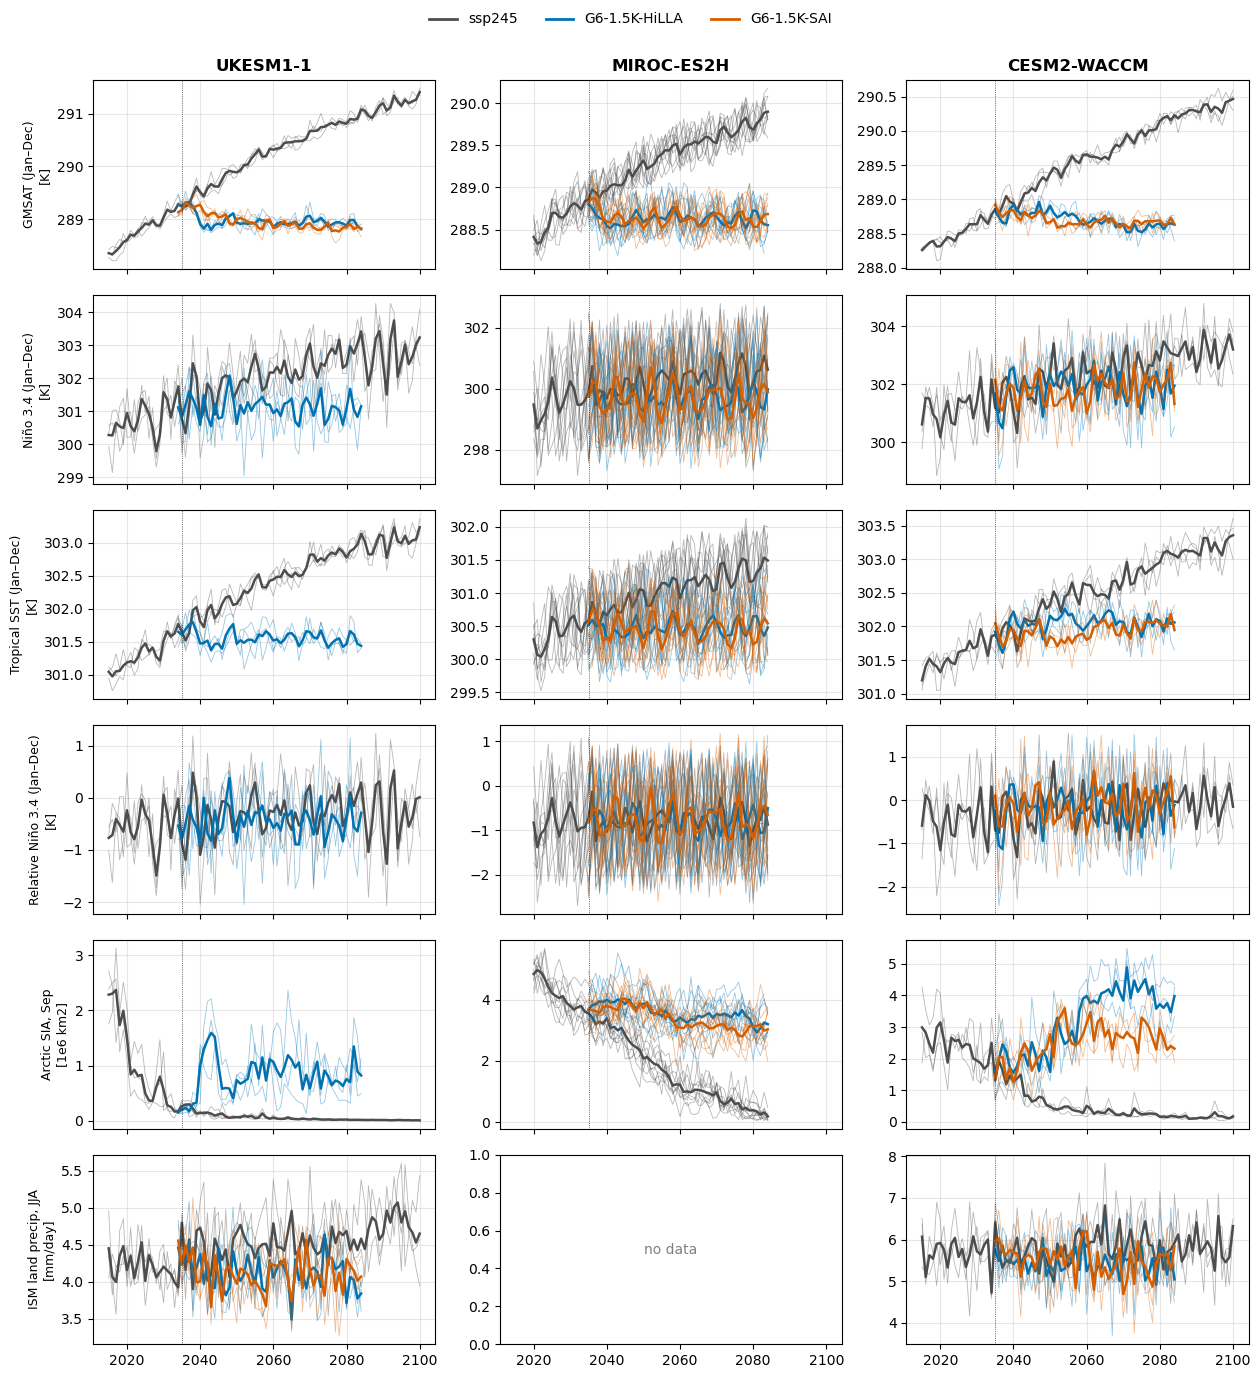

In [13]:
# 6a. Calendar-year indices (Sep sea ice, JJA monsoon): thin = members, thick = ensemble mean
fig, axes = plt.subplots(len(ANNUAL_INDICES), len(MODELS), figsize=(4.2 * len(MODELS), 2.3 * len(ANNUAL_INDICES)),
                         sharex=True, squeeze=False)
for j, model in enumerate(MODELS):
    a = ds_ann[model]
    for i, k in enumerate(ANNUAL_INDICES):
        ax = axes[i, j]
        if k not in a:
            ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes, color="0.5")
            continue
        for scen in PLOT_SCENARIOS:
            if scen not in a.scenario.values:
                continue
            s = a[k].sel(scenario=scen)
            for mem in s.member.values:
                ax.plot(s.year, s.sel(member=mem), color=SCEN_COLOURS[scen], lw=0.6, alpha=0.4)
            ax.plot(s.year, s.mean("member"), color=SCEN_COLOURS[scen], lw=1.8)
        ax.axvline(2035, color="k", lw=0.5, ls=":")
        if j == 0:
            ax.set_ylabel(f"{LABELS[k]}\n[{UNITS[k]}]", fontsize=9)
        if i == 0:
            ax.set_title(model, fontweight="bold")
        ax.grid(alpha=0.3)
fig.legend(handles=legend_handles(), loc="upper center", ncol=len(PLOT_SCENARIOS), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIG / "annual_indices.png", dpi=150)
plt.show()

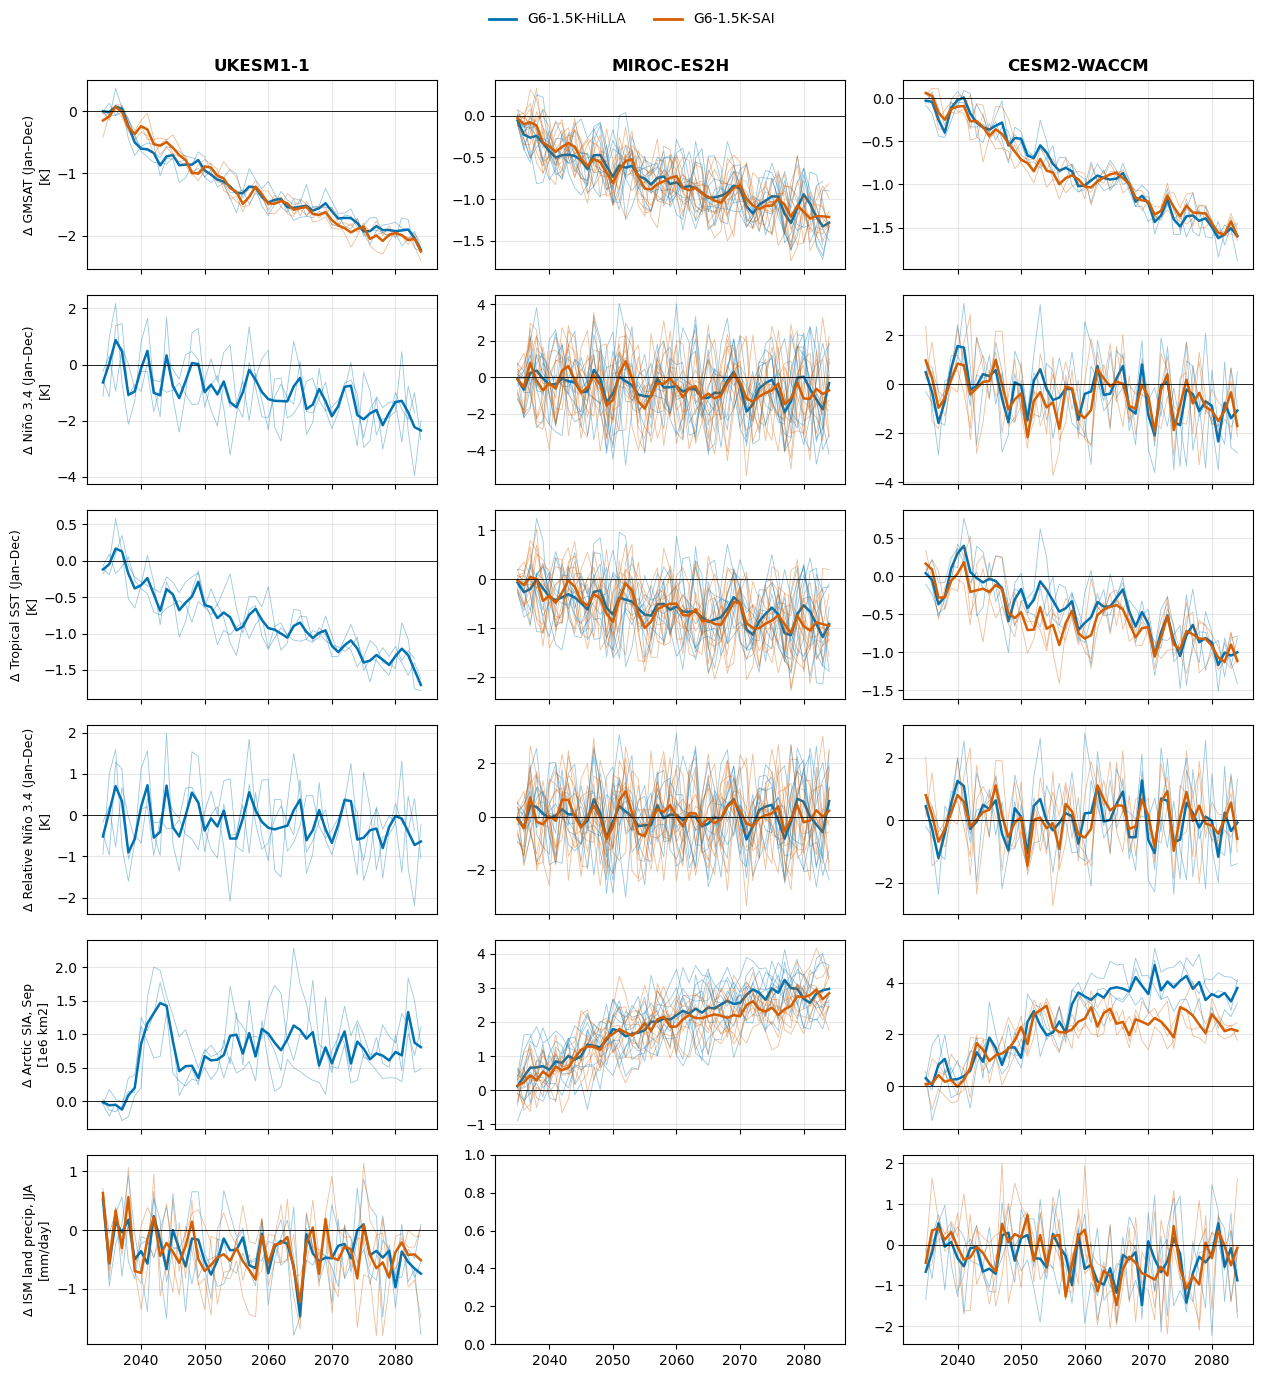

In [14]:
# 6b. Paired differences (SAI member rN minus ssp245 member rN): thin = members, thick = mean
fig, axes = plt.subplots(len(ANNUAL_INDICES), len(MODELS), figsize=(4.2 * len(MODELS), 2.3 * len(ANNUAL_INDICES)),
                         sharex=True, squeeze=False)
for j, model in enumerate(MODELS):
    a = ds_ann[model]
    for i, k in enumerate(ANNUAL_INDICES):
        ax = axes[i, j]
        if k not in a or "ssp245" not in a.scenario.values:
            continue
        for scen in SAI_SCENARIOS:
            if scen not in a.scenario.values:
                continue
            d = a[k].sel(scenario=scen) - a[k].sel(scenario="ssp245")
            d = d.dropna("year", how="all")
            for mem in d.member.values:
                ax.plot(d.year, d.sel(member=mem), color=SCEN_COLOURS[scen], lw=0.6, alpha=0.4)
            ax.plot(d.year, d.mean("member"), color=SCEN_COLOURS[scen], lw=1.8)
        ax.axhline(0, color="k", lw=0.6)
        if j == 0:
            ax.set_ylabel(f"Δ {LABELS[k]}\n[{UNITS[k]}]", fontsize=9)
        if i == 0:
            ax.set_title(model, fontweight="bold")
        ax.grid(alpha=0.3)
fig.legend(handles=legend_handles()[1:], loc="upper center", ncol=len(SAI_SCENARIOS), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIG / "paired_differences.png", dpi=150)
plt.show()

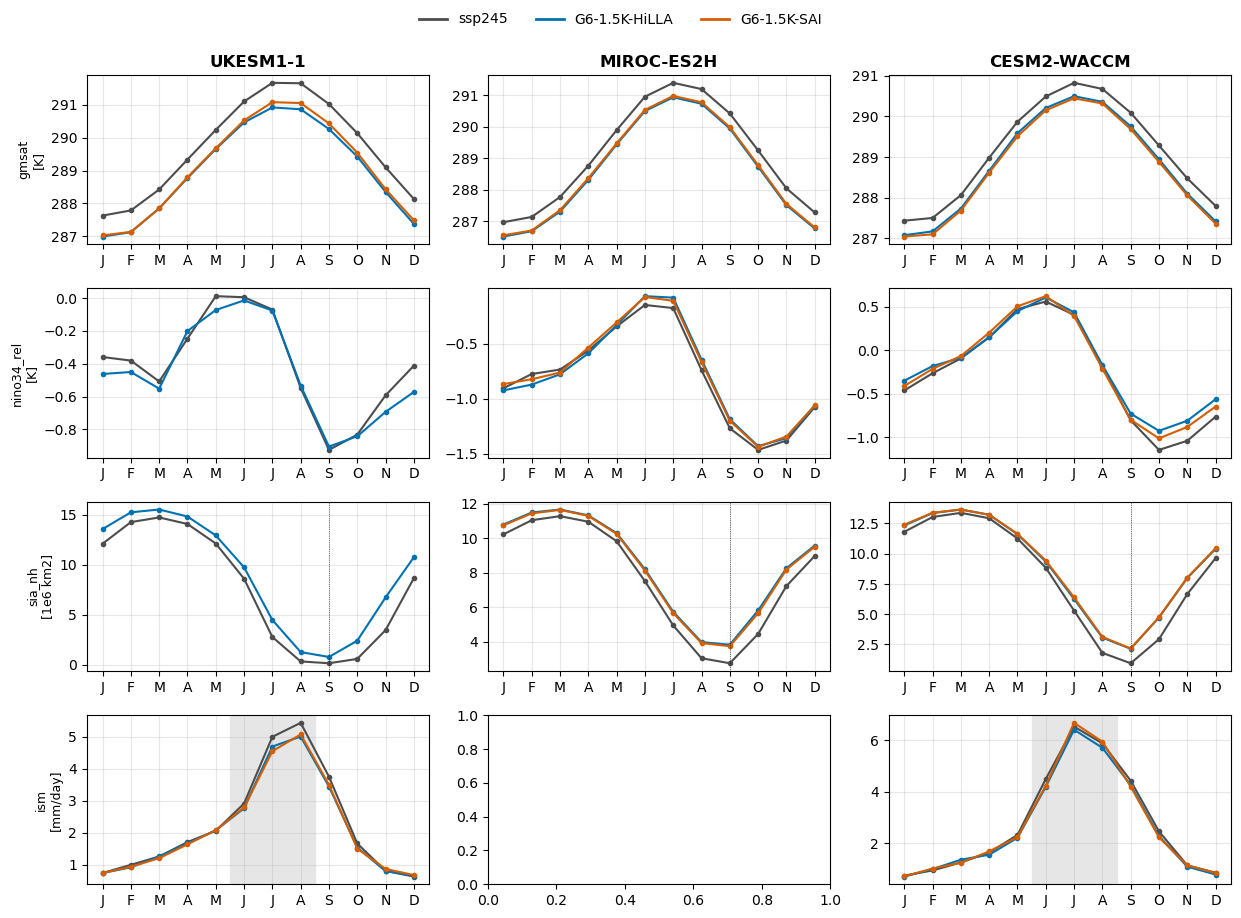

In [15]:
# 6c. Seasonal cycles (ensemble mean, first 20 years of each scenario from 2035)
SEASONAL = [("gmsat", "K"), ("nino34_rel", "K"), ("sia_nh", "1e6 km2"), ("ism", "mm/day")]
fig, axes = plt.subplots(len(SEASONAL), len(MODELS), figsize=(4.2 * len(MODELS), 2.3 * len(SEASONAL)),
                         squeeze=False)
for j, model in enumerate(MODELS):
    m = ds_mon[model]
    m = m.isel(time=((m.time.dt.year >= 2035) & (m.time.dt.year <= 2054)).values)
    for i, (k, u) in enumerate(SEASONAL):
        ax = axes[i, j]
        if k not in m:
            continue
        for scen in PLOT_SCENARIOS:
            if scen not in m.scenario.values:
                continue
            clim = m[k].sel(scenario=scen).mean("member").groupby("time.month").mean()
            ax.plot(clim.month, clim, marker="o", ms=3, color=SCEN_COLOURS[scen])
        ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
        if k == "sia_nh":
            ax.axvline(9, color="k", lw=0.5, ls=":")
        if k == "ism":
            ax.axvspan(5.5, 8.5, color="0.9", zorder=0)
        if j == 0:
            ax.set_ylabel(f"{k}\n[{u}]", fontsize=9)
        if i == 0:
            ax.set_title(model, fontweight="bold")
        ax.grid(alpha=0.3)
fig.legend(handles=legend_handles(), loc="upper center", ncol=len(PLOT_SCENARIOS), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG / "seasonal_cycles.png", dpi=150)
plt.show()

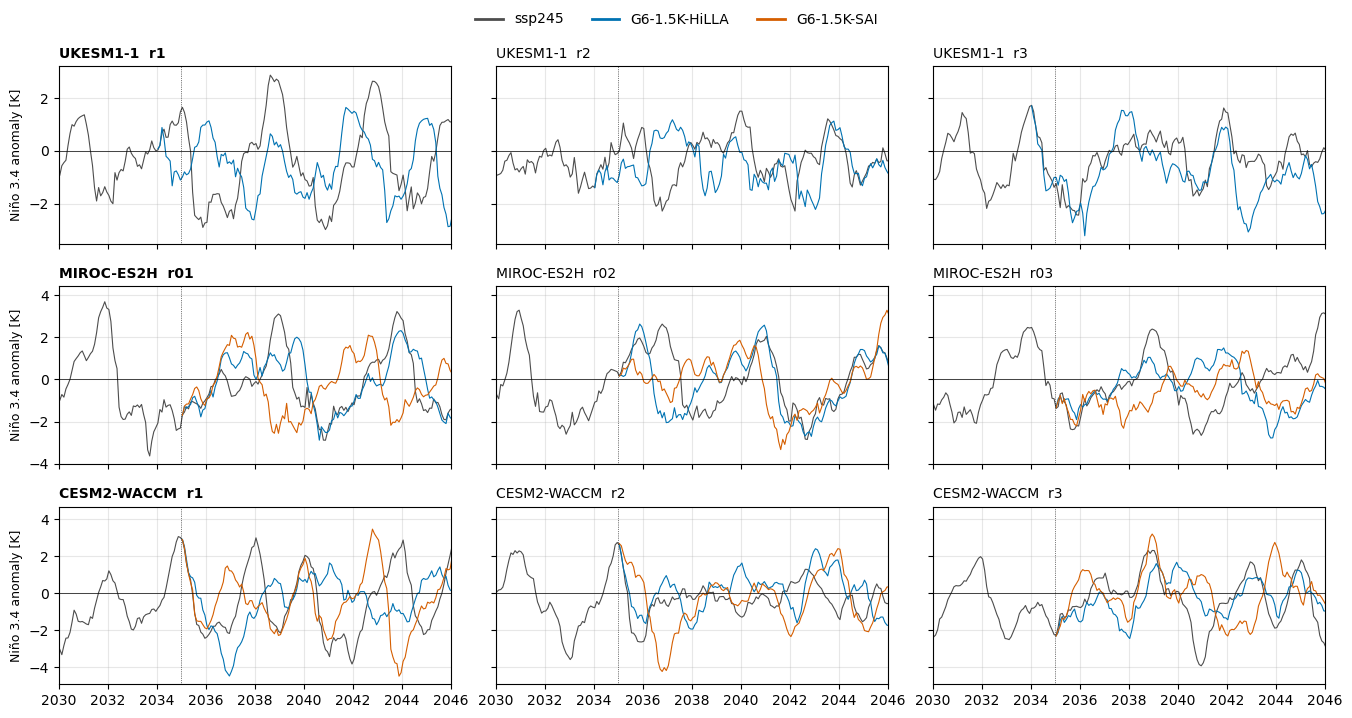

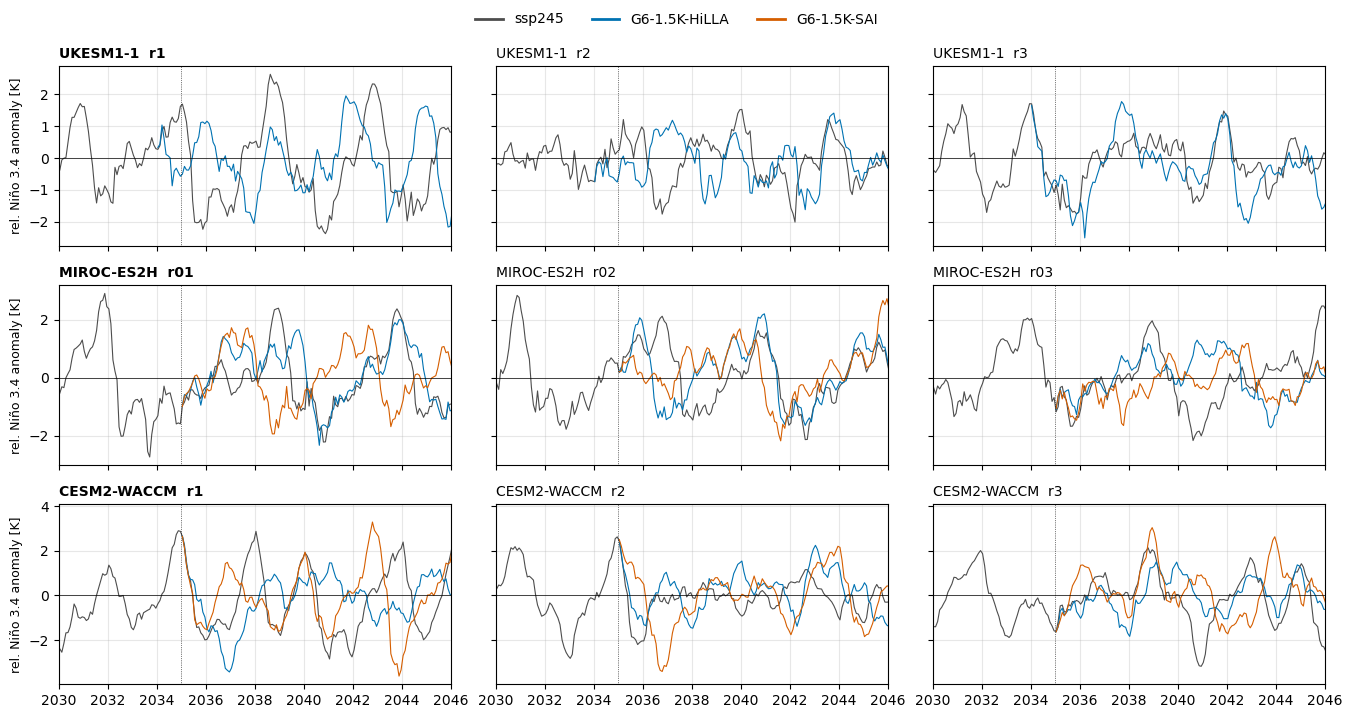

In [16]:
# 6d. Monthly ENSO indices, shown 2030-2045: rows = models, columns = first 3 members with data.
# One figure for the absolute Nino 3.4 index, one for the relative index.
# Anomalies are relative to the same member's ssp245 monthly climatology over the window,
# for every scenario, so SAI-minus-ssp245 offsets stay visible. If that member has no
# ssp245 series, each series' own climatology is used instead (title marked *).
WINDOW = (2030, 2060)   # period for the ssp245 climatology the anomalies are taken from
XLIM = (2030, 2045)     # period shown
N_MEMBERS = 3
ENSO_PLOTS = {"nino34": "Niño 3.4 anomaly [K]", "nino34_rel": "rel. Niño 3.4 anomaly [K]"}

def in_window(da):
    return da.isel(time=((da.time.dt.year >= WINDOW[0]) & (da.time.dt.year <= WINDOW[1])).values)

def decimal_year(time):
    return [t.year + (t.month - 0.5) / 12 for t in time.values]

for var, ylabel in ENSO_PLOTS.items():
    fig, axes = plt.subplots(len(MODELS), N_MEMBERS, figsize=(4.5 * N_MEMBERS, 2.4 * len(MODELS)),
                             sharex=True, sharey="row", squeeze=False)
    for i, model in enumerate(MODELS):
        m = ds_mon[model]
        da = in_window(m[var]) if var in m else None
        members = [] if da is None else [
            v for v in da.member.values if da.sel(member=v).notnull().any()][:N_MEMBERS]
        for j in range(N_MEMBERS):
            ax = axes[i, j]
            if j >= len(members):
                ax.text(0.5, 0.5, f"{model}: no data", ha="center", va="center",
                        transform=ax.transAxes, color="0.5")
                continue
            mem = members[j]
            ref = da.sel(scenario="ssp245", member=mem) if "ssp245" in da.scenario.values else None
            ref_ok = ref is not None and int(ref.notnull().sum()) >= 24
            for scen in PLOT_SCENARIOS:
                if scen not in da.scenario.values:
                    continue
                s = da.sel(scenario=scen, member=mem).dropna("time")
                if s.size == 0:
                    continue
                clim = (ref if ref_ok else s).groupby("time.month").mean()
                anom = s.groupby("time.month") - clim
                ax.plot(decimal_year(anom.time), anom, color=SCEN_COLOURS[scen], lw=0.8)
            ax.axhline(0, color="k", lw=0.5)
            ax.axvline(2035, color="k", lw=0.5, ls=":")
            ax.set_xlim(XLIM[0], XLIM[1] + 1)
            ax.set_title(f"{model}  {mem}" + ("" if ref_ok else "  *"), loc="left",
                         fontsize=10, fontweight="bold" if j == 0 else "normal")
            if j == 0:
                ax.set_ylabel(ylabel, fontsize=9)
            ax.grid(alpha=0.3)
    fig.legend(handles=legend_handles(), loc="upper center", ncol=len(PLOT_SCENARIOS), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(FIG / f"enso_monthly_{var}.png", dpi=150)
    plt.show()

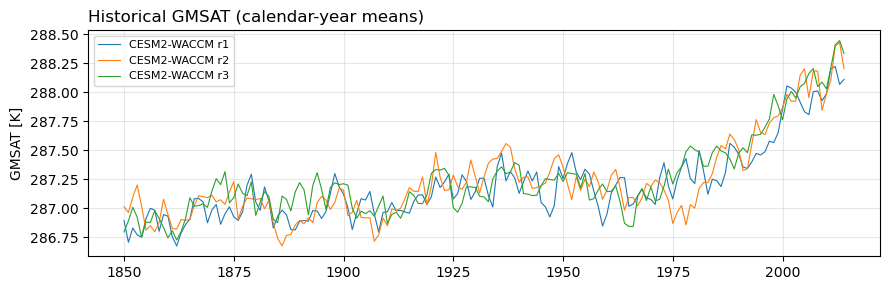

In [17]:
# 6e. Historical GMSAT (models with a historical scenario)
hist_models = [m for m in MODELS if "historical" in ds_ann[m].scenario.values]
if hist_models:
    fig, ax = plt.subplots(figsize=(9, 3))
    for model in hist_models:
        s = ds_ann[model].gmsat.sel(scenario="historical")
        for mem in s.member.values:
            ax.plot(s.year, s.sel(member=mem), lw=0.8, label=f"{model} {mem}")
    ax.set_ylabel("GMSAT [K]")
    ax.set_title("Historical GMSAT (calendar-year means)", loc="left")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG / "historical_gmsat.png", dpi=150)
    plt.show()

In [18]:
from inputs import load_member, get_latlon
row = present[(present.model == "MIROC-ES2H") & (present.role == "precip")].iloc[0]
da = load_member(row)["pr"]
sft = fx[("MIROC-ES2H", "sftlf")]
lat_d, lon_d = get_latlon(da.to_dataset())
lat_f, lon_f = get_latlon(sft.to_dataset())
print("data  lat:", lat_d.values[:3], "...", lat_d.values[-3:])
print("sftlf lat:", lat_f.values[:3], "...", lat_f.values[-3:])
print("data  lon:", lon_d.values[:3], "   sftlf lon:", lon_f.values[:3])
print("sftlf min/max:", float(sft.min()), float(sft.max()), " NaNs:", int(sft.isnull().sum()))

data  lat: [88.92773535 87.53870521 86.1414721 ] ... [-86.1414721  -87.53870521 -88.92773535]
sftlf lat: [-88.92773535 -87.53870521 -86.1414721 ] ... [86.1414721  87.53870521 88.92773535]
data  lon: [0.      1.40625 2.8125 ]    sftlf lon: [0.      1.40625 2.8125 ]


sftlf min/max: 0.0 100.0  NaNs: 0
